# Aplikasi Rekomendasi Citra Serupa — Tahap 1: dataset dan preprocessing

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Prodi-TI-IBIKesatuan/pcd2026-ti23ka-t5/blob/main/notebooks/01_dataset_preprocessing.ipynb)

Kelompok `pcd2026-ti23ka-t5` · 4 anggota · minimal **200 citra** (termasuk 60 foto sendiri).

Notebook ini membaca dataset dari folder Google Drive kelompok, memeriksa anotasi, menerapkan preprocessing, dan menyimpan gambar sebelum–sesudah. Jalankan dari atas ke bawah.

In [1]:
# Siapkan lingkungan: salin repo ini dan hubungkan Google Drive kelompok.
import pathlib
import subprocess
import sys

import cv2
import numpy as np

REPO = "Prodi-TI-IBIKesatuan/pcd2026-ti23ka-t5"
try:
    import google.colab  # noqa: F401
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

if DI_COLAB:
    AKAR = pathlib.Path("/content/repo")
    if AKAR.exists():
        subprocess.run(["git", "-C", str(AKAR), "pull", "-q"], check=False)
    else:
        subprocess.run(["git", "clone", "-q", "--depth", "1", f"https://github.com/{REPO}.git", str(AKAR)], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    FOLDER_KERJA = pathlib.Path("/content/drive/MyDrive/pcd2026-ti23ka-t5")
    if not FOLDER_KERJA.exists():
        raise FileNotFoundError(f"{FOLDER_KERJA} tidak ada. Tambahkan pintasan folder Drive kelompok ke Drive Saya (lihat PANDUAN.md).")
else:  # dijalankan di komputer sendiri dari folder notebooks/
    AKAR = pathlib.Path.cwd().resolve().parent
    FOLDER_KERJA = AKAR / "data"
sys.path.insert(0, str(AKAR))

from pcd_proyek import evaluasi as ev, metrik, util  # noqa: E402

FOLDER_CITRA = FOLDER_KERJA / "citra" if (FOLDER_KERJA / "citra").exists() else AKAR / "data" / "sample"
BERKAS_ANOTASI = FOLDER_KERJA / "anotasi.csv"
FOLDER_FIGUR = FOLDER_KERJA / "figures"
BERKAS_HASIL = FOLDER_KERJA / "hasil_metode.json"
KOLOM_ANOTASI = ['berkas', 'kategori']
JUMLAH_ANGGOTA = 4
print("Citra   :", FOLDER_CITRA)
print("Anotasi :", BERKAS_ANOTASI, "(ada)" if BERKAS_ANOTASI.exists() else "(belum ada)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Citra   : /content/drive/MyDrive/pcd2026-ti23ka-t5/citra
Anotasi : /content/drive/MyDrive/pcd2026-ti23ka-t5/anotasi.csv (ada)


## 1. Statistik dataset

200 citra (200 terbaca); minimal 200 untuk kelompok ini
Lebar : {'min': 332, 'median': 679, 'maks': 5259}
Tinggi: {'min': 333, 'median': 683, 'maks': 4032}


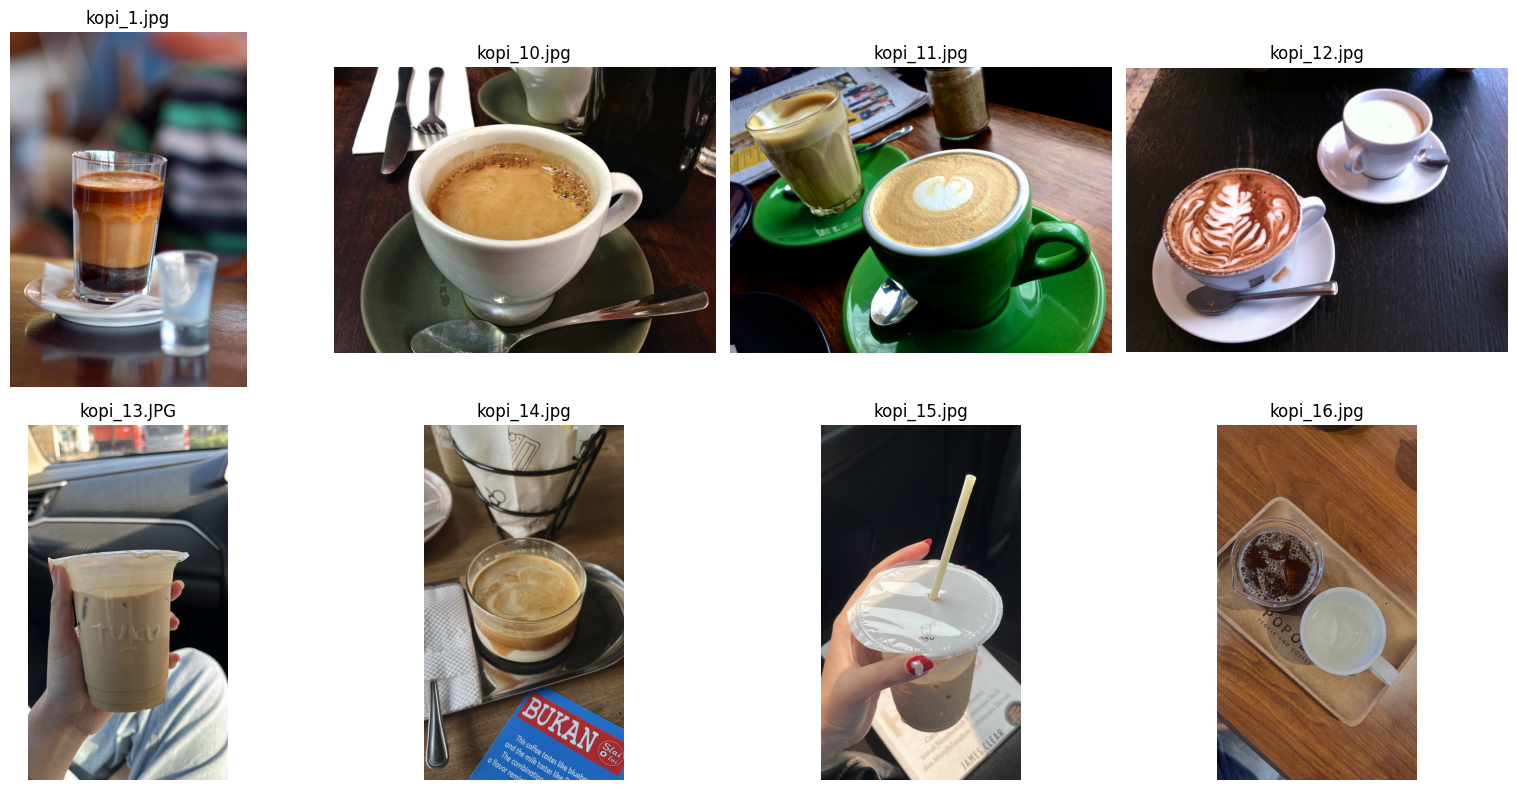

In [2]:
berkas = util.daftar_citra(FOLDER_CITRA)
if not berkas:
    raise RuntimeError(f"Tidak ada citra di {FOLDER_CITRA}")
stat = util.statistik_dataset(berkas)
print(f"{stat['jumlah']} citra ({stat['terbaca']} terbaca); minimal 200 untuk kelompok ini")
print("Lebar :", stat.get("lebar"))
print("Tinggi:", stat.get("tinggi"))
if stat["gagal"]:
    print("Gagal dibaca (hapus atau ganti):", *stat["gagal"][:10], sep="\n  ")
util.tampil(*[util.baca_citra(p) for p in berkas[:8]], judul=[p.name for p in berkas[:8]], kolom=4)

## 2. Cek anotasi

Label kategori setiap citra; dua citra dianggap relevan bila kategorinya sama.

Kolom `anotasi.csv` (persis): `berkas, kategori`. Contoh baris ada di `data/format_anotasi.csv`.

In [3]:
KOLOM_BERKAS = ['berkas']
if BERKAS_ANOTASI.exists():
    anotasi = util.baca_anotasi(BERKAS_ANOTASI, KOLOM_ANOTASI)
    cek = util.cek_anotasi(anotasi, FOLDER_CITRA, KOLOM_BERKAS)
    print(len(anotasi), "baris anotasi")
    print("Disebut di anotasi tetapi berkasnya tidak ada:", cek["hilang"][:20])
    print("Citra belum beranotasi:", len(cek["tanpa_anotasi"]), cek["tanpa_anotasi"][:10])
else:
    print("anotasi.csv belum ada di", BERKAS_ANOTASI)

200 baris anotasi
Disebut di anotasi tetapi berkasnya tidak ada: []
Citra belum beranotasi: 0 []


## 3. Preprocessing

Saran untuk topik ini: resize seragam; normalisasi warna; penghapusan duplikat.

Sel kode di bawah hanya **kerangka dummy**. Ganti dengan langkah preprocessing kelompok, lalu tulis **alasan setiap langkah** dan parameternya di sel markdown sesudahnya.

In [4]:
def praproses(citra):
    """
    Preprocessing dataset beverages:
    1. Resize maksimal 768 piksel.
    2. Contrast stretching pada kanal kecerahan.
    3. Mempertahankan rasio aspek asli.
    """

    # 1. Resize maksimal 768 piksel
    citra = util.ubah_ukuran_maks(citra, 768)

    # 2. Contrast stretching pada kanal kecerahan
    hsv = cv2.cvtColor(citra, cv2.COLOR_BGR2HSV)

    h, s, v = cv2.split(hsv)

    v = cv2.normalize(
        v, None, 0, 255, cv2.NORM_MINMAX
    )

    hsv = cv2.merge((h, s, v))
    citra = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    return citra


# 3. Pemeriksaan Duplikat menggunakan SHA-256
import hashlib

hash_gambar = {}
duplikat = []

for p in berkas:
    checksum = hashlib.sha256(p.read_bytes()).hexdigest()

    if checksum in hash_gambar:
        duplikat.append((p, hash_gambar[checksum]))
    else:
        hash_gambar[checksum] = p

print("Jumlah gambar:", len(berkas))
print("Jumlah duplikat:", len(duplikat))

if duplikat:
    print("\nGambar duplikat yang ditemukan:")
    for gambar, asli in duplikat:
        print(gambar.name, "duplikat dari", asli.name)
else:
    print("Tidak ditemukan gambar duplikat.")

Jumlah gambar: 200
Jumlah duplikat: 0
Tidak ditemukan gambar duplikat.


Alasan Langkah Preprocessing

Preprocessing dataset beverages dilakukan melalui tiga tahapan:

1. Resize: Mengubah ukuran gambar dengan batas maksimal 768 piksel pada sisi terpanjang. Rasio aspek asli dipertahankan agar bentuk objek minuman tidak berubah dan gambar tidak terpotong.

2. Contrast Stretching: Meningkatkan rentang kontras menggunakan normalisasi min-max pada kanal kecerahan (V) dalam ruang warna HSV, dengan rentang intensitas 0–255. Proses ini bertujuan memperjelas perbedaan tingkat kecerahan tanpa mengubah nilai hue dan saturation secara langsung.

3. Pemeriksaan Duplikat: Menggunakan algoritma SHA-256 untuk membandingkan isi setiap berkas gambar. Gambar dengan hash identik akan teridentifikasi sebagai duplikat sehingga dapat diperiksa dan ditindaklanjuti.

Ketiga tahapan bertujuan menghasilkan dataset yang lebih konsisten, memiliki ukuran yang lebih efisien, serta mengurangi duplikasi gambar identik.

## 4. Gambar sebelum–sesudah

Sel ini menyimpan 12 contoh ke folder `figures/` di Drive. Unggah minimal 10 ke `outputs/figures/` di repo (lihat `PANDUAN.md`).

12 gambar di /content/drive/MyDrive/pcd2026-ti23ka-t5/figures


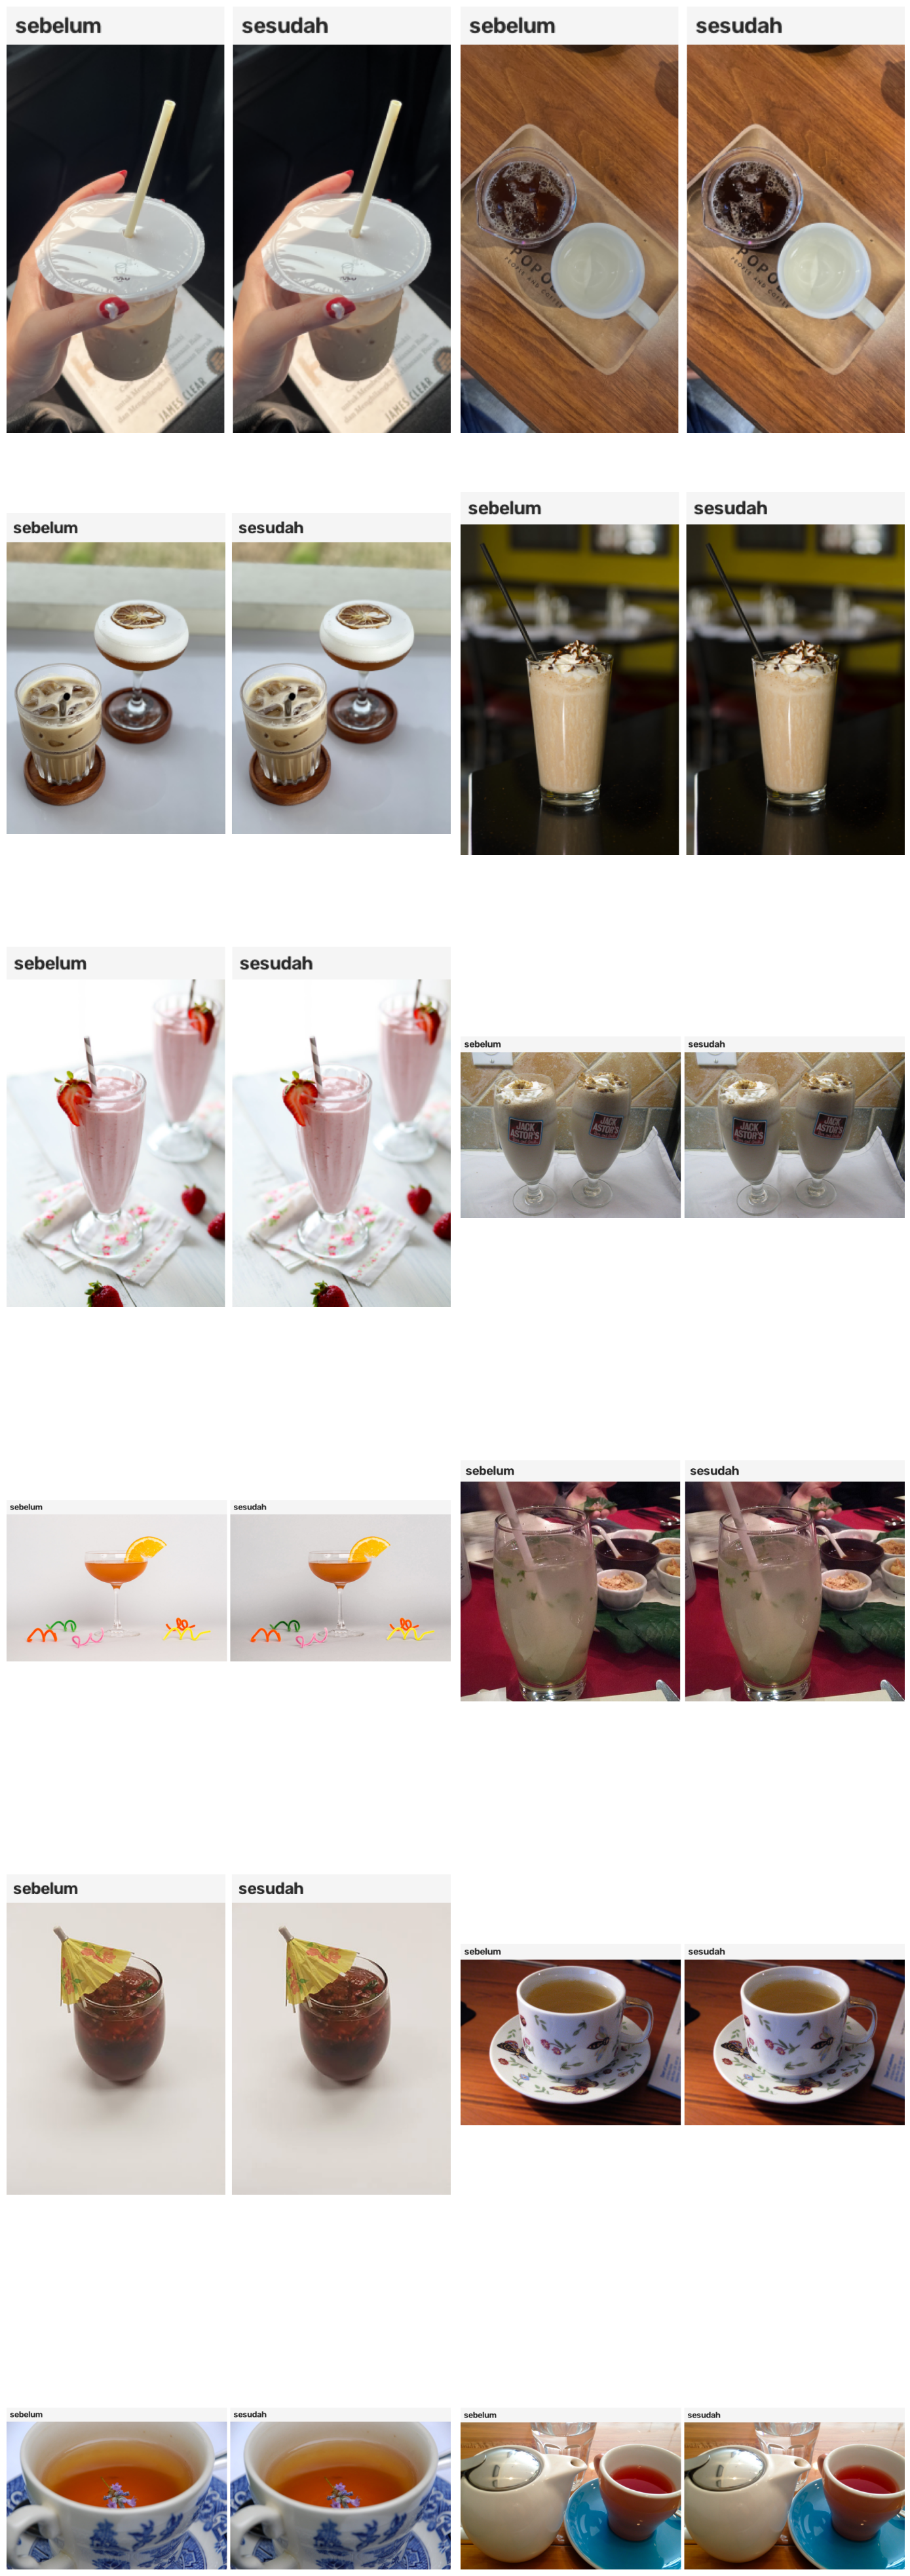

In [5]:
FOLDER_FIGUR.mkdir(parents=True, exist_ok=True)

# Hapus hasil preprocessing sebelumnya
for f in FOLDER_FIGUR.glob("pra_*.png"):
    f.unlink()

# Saya ganti karena ingin menampilkan 3 foto dari 4 kategori yang ada
nama_berkas = [
    "Kopi/kopi_15.jpg",
    "Kopi/kopi_16.jpg",
    "Kopi/kopi_17.jpg",
    "Milkshake/milkshake_15.jpg",
    "Milkshake/milkshake_16.jpg",
    "Milkshake/milkshake_17.jpg",
    "Mocktails/mocktails_15.jpg",
    "Mocktails/mocktails_16.jpg",
    "Mocktails/mocktails_17.jpg",
    "Tea/tea_15.jpg",
    "Tea/tea_16.jpg",
    "Tea/tea_17.jpg"
]

for p in [p for p in berkas if any(p.as_posix().endswith(n) for n in nama_berkas)]:
    asli = util.ubah_ukuran_maks(util.baca_citra(p), 1024)
    util.simpan_sebelum_sesudah(asli, praproses(asli), FOLDER_FIGUR / f"pra_{p.stem}.png")
contoh = sorted(FOLDER_FIGUR.glob("pra_*.png"))[:12]
print(len(list(FOLDER_FIGUR.glob("pra_*.png"))), "gambar di", FOLDER_FIGUR)
util.tampil(*[util.baca_citra(f) for f in contoh], kolom=2, ukuran=7)

## Simpan ke GitHub

1. **Runtime → Restart session and run all**, pastikan tidak ada error.
2. **File → Download → Download .ipynb**, lalu di github.com pilih **branch Anda** → folder `notebooks/` → **Add file → Upload files** → commit ke branch Anda. (Bila menu Colab menampilkan *Save a copy in GitHub*, itu juga boleh. Jangan pakai *GitHub Gist*.)
3. Buka *pull request* ke `main` di github.com. Langkah lengkap: `PANDUAN.md`.